#### 문제 01

공장 장비의 압력값 x에 따른 비용함수가 다음과 같음.

$$
L(x)=4x^3-3x^2+2x
$$

x=2일 때 비용함수의 값과 미분값을 구하기.

**요구사항**
1. x를 `requires_grad=True`로 생성.
2. 손실함수 L 계산.
3. L과 `x.grad` 출력.

In [2]:
import torch

In [24]:
x = torch.tensor([2.], requires_grad=True)
l = 4*x**3 - 3*x**2 + 2*x
l.backward()
print(l)
print(x.grad)

tensor([24.], grad_fn=<AddBackward0>)
tensor([38.])


#### 문제 02

세 개의 입력값을 가진 함수가 다음과 같음.

$$
L=3x_1^2-2x_2^2+5x_3
$$

입력값은 x=[-1, 2, 4]임.

**요구사항**
1. x를 `requires_grad=True`인 1차원 텐서로 생성.
2. 위 함수의 결과를 계산.
3. 각 입력 원소에 대한 기울기 출력.

In [13]:
x = torch.tensor([-1., 2, 4], requires_grad=True)
l = 3*x[0]**2 - 2*x[1]**2 + 5 * x[2]
print(l)

l.backward()
print(x.grad[0])
print(x.grad[1])
print(x.grad[2])

tensor(15., grad_fn=<AddBackward0>)
tensor(-6.)
tensor(-8.)
tensor(5.)


#### 문제 03

두 변수 x, y에 대한 함수가 다음과 같음.

$$
f(x,y)=x^2y+3xy^2+y
$$

x=2, y=-1일 때 각 변수에 대한 편미분값 구하기.

**요구사항**
1. x와 y를 각각 `requires_grad=True`로 생성.
2. 함수 f 계산.
3. x와 y의 기울기 출력.

In [46]:
x = torch.tensor([2.], requires_grad=True)
y = torch.tensor([-1.], requires_grad=True)
f = x**2*y + 3*x*y**2 + y
f.backward()
print(x.grad)
print(y.grad)

tensor([-1.])
tensor([-7.])


#### 문제 04

다음과 같이 연산이 연결된 함수가 있음.

$$
a=2x+1,\quad b=a^3,\quad L=\sqrt{b}
$$

x=4일 때 L과 x에 대한 미분값 구하기.

**요구사항**
1. x를 `requires_grad=True`로 생성.
2. a, b, L을 순서대로 계산.
3. 중간 결과와 x.grad 출력.

**제약:** 연산을 하나의 식으로 합치지 말고 중간 텐서를 각각 생성하기.

In [23]:
x = torch.tensor([4.], requires_grad=True)
a = 2 * x + 1
b = a ** 3
l = torch.sqrt(b)

l.backward()

print(a)
print(b)
print(l)

print(x.grad)

tensor([9.], grad_fn=<AddBackward0>)
tensor([729.], grad_fn=<PowBackward0>)
tensor([27.], grad_fn=<SqrtBackward0>)
tensor([9.])


#### 문제 05

세 개의 예측값과 실제값 사이의 제곱오차 평균을 계산하려고 함.

```python
pred = torch.tensor([2.0, 4.0, 6.0], requires_grad=True)
target = torch.tensor([1.0, 3.0, 5.0])
```

**요구사항**
1. 각 예측값과 실제값의 차이를 제곱.
2. 제곱오차의 평균을 손실함수로 계산.
3. 손실값과 `pred.grad` 출력.

**제약:** 평균 제곱 오차는 `(pred - target) ** 2`의 평균으로 계산하기.

In [47]:

pred = torch.tensor([2., 4, 6], requires_grad=True)
target = torch.tensor([1., 3, 5])
squared_error = (pred - target) ** 2
loss = torch.mean(squared_error)
loss.backward()
print(loss)
print(pred.grad)

tensor(1., grad_fn=<MeanBackward0>)
tensor([0.6667, 0.6667, 0.6667])


#### 문제 06

하나의 텐서에 대해 두 번 역전파를 실행하여 기울기 누적을 확인하기.

**요구사항**
1. x=[2, 3]을 `requires_grad=True`로 생성.
2. `a = (x ** 2).sum()`을 계산하고 역전파.
3. `b = (4 * x).sum()`을 계산하고 다시 역전파.
4. 누적된 기울기 출력.
5. `x.grad.zero_()`로 초기화한 뒤 기울기 출력.

In [26]:
x = torch.tensor([2.,3], requires_grad=True)
a = (x ** 2).sum()
a.backward()
print(x.grad)
b = (4 * x ).sum()
b.backward()
print(x.grad)
x.grad.zero_()
print(x.grad)

tensor([4., 6.])
tensor([ 8., 10.])
tensor([0., 0.])


#### 문제 07

벡터 출력의 각 원소에 서로 다른 기울기를 전달하기.

```python
x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
y = x ** 3
```

**요구사항**
1. `gradient` 텐서를 `[1.0, 0.5, -1.0]`으로 생성.
2. `y.backward(gradient)` 실행.
3. x.grad 출력.

**제약:** `y.sum().backward()`를 사용하지 않기.

tensor([ 1.,  8., 27.], grad_fn=<PowBackward0>)
tensor([  3.,   6., -27.])


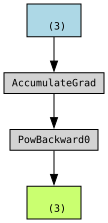

In [48]:
x = torch.tensor([1., 2, 3], requires_grad=True)
y = x ** 3
print(y)
# gradient = torch.autograd.grad(y, x)    # RuntimeError: grad can be implicitly created only for scalar outputs
gradient = torch.tensor([1., 0.5, -1], requires_grad=True)
y.backward(gradient)    # gradient는 벡터 출력의 기울기 계산의 upstream gradient임
print(x.grad)

from torchviz import make_dot
make_dot(y)

#### 문제 08

하나의 입력값으로 여러 단계의 연산을 수행하는 함수 구현

$$
a=3x-1,\quad b=a^2,\quad L=2b+5
$$

x=2일 때 L과 각 중간 텐서의 기울기를 확인하기.

**요구사항**
1. x를 `requires_grad=True`로 생성.
2. a, b, L을 순서대로 계산.
3. `a.retain_grad()`와 `b.retain_grad()`를 사용하여 중간 텐서의 기울기도 저장.
4. `L.backward()` 실행.
5. L, x.grad, a.grad, b.grad 출력.

In [40]:
x = torch.tensor([2.], requires_grad=True)
a = 3 * x - 1
b = a ** 2
loss = 2 * b + 5

a.retain_grad()
b.retain_grad()
loss.backward()

print(loss) # grad_fn = <AddBackward0> 하나만 출력
# grad_fn represents the operation that created a tensor, 
# not the complete sequence of operations performed on x.
print(x.grad)
print(a.grad)
print(b.grad)

print(a.grad_fn)
print(b.grad_fn)
print(loss.grad_fn)

tensor([55.], grad_fn=<AddBackward0>)
tensor([60.])
tensor([20.])
tensor([2.])


#### 문제 09

두 변수 x, z에 대한 함수가 다음과 같음.

$$
f(x,z)=x^2z+3z^2+4x
$$

x=3, z=2일 때 `torch.autograd.grad()`를 이용하여 각 변수에 대한 편미분값 구하기.

**요구사항**
1. x와 z를 각각 `requires_grad=True`로 생성.
2. 함수 f 계산.
3. `torch.autograd.grad()`를 사용하여 x와 z에 대한 기울기를 한 번에 계산.
4. f와 반환된 기울기를 출력.
5. `x.grad`와 `z.grad`도 출력하여 값이 저장되었는지 확인.

**제약:** `f.backward()`를 사용하지 않기.

In [ ]:
x = torch.tensor([3.], requires_grad=True)
z = torch.tensor([2.], requires_grad=True)
f = x**z + 3 * z ** 2 + 4 * x

gradient = torch.autograd.grad(f, [x,z])
print(f)
print(gradient)
print(x.grad) # 저장 안됨 ( backward() 사용 안함 )
print(z.grad) # 저장 안됨 ( backward() 사용 안함 )

tensor([33.], grad_fn=<AddBackward0>)
(tensor([10.]), tensor([21.8875]))
None
None


#### 문제 10

`torch.no_grad()`와 `requires_grad=False`의 차이를 확인하기.

**요구사항**
1. x를 값이 2.0이고 `requires_grad=True`인 텐서로 생성.
2. 일반적인 연산으로 `a = x**2` 계산.
3. `torch.no_grad()` 블록 안에서 `b = 3*x + 2` 계산.
4. `c = a + b`를 계산하고 `c.backward()` 실행.
5. x, a, b, c의 `requires_grad`와 b의 `grad_fn`을 출력.
6. x.grad를 출력.
7. 별도의 텐서 u를 값이 3.0이고 `requires_grad=True`로 생성한 뒤, `u.requires_grad = False`로 변경.
8. `v = u**2`를 계산하고 u와 v의 `requires_grad`, v의 `grad_fn`을 출력.

In [45]:
x = torch.tensor([2.], requires_grad=True)
a = x ** 2
with torch.no_grad():
    b = 3 * x + 2
c = a + b
c.backward()

print(x.requires_grad)
print(a.requires_grad)
print(b.requires_grad)
print(c.requires_grad)
print(b.grad_fn)

print(x.grad)

u = torch.tensor([3.], requires_grad=True)
u.requires_grad = False
v = u ** 2
# v.backward() 불가능 
print(u.requires_grad)
print(v.requires_grad)
print(v.grad_fn)

True
True
False
True
None
tensor([4.])
False
False
None
